In [2]:
Sys.setenv(RETICULATE_PYTHON = "/usr/bin/python3")

library(reticulate)
use_python("/usr/bin/python3", required = TRUE)
py_module_available("tensorflow")

[1] TRUE

In [3]:
library(EBImage)
library(keras3)
tf_version <- tensorflow::tf_version(); tf_version


Attaching package: ‘keras3’


The following object is masked from ‘package:EBImage’:

    normalize




[1] ‘2.21’

In [7]:
system("pip install -q pillow-avif-plugin")

library(reticulate)
py_run_string("
import glob
try:
    import pillow_avif
except ImportError:
    pass
from PIL import Image
for f in glob.glob('/content/*.jpg'):
    Image.open(f).convert('RGB').save(f, 'JPEG')
")

system("file /content/*.jpg")

In [9]:
list.files("/content", pattern = "\\.jpg$")
print(system("file /content/*.jpg", intern = TRUE))

[1] "b1.jpg" "b2.jpg" "b3.jpg" "b4.jpg" "b5.jpg" "b6.jpg" "c1.jpg" "c2.jpg"
 [9] "c3.jpg" "c4.jpg" "c5.jpg" "c6.jpg" "p1.jpg" "p2.jpg" "p3.jpg" "p4.jpg"
[17] "p5.jpg" "p6.jpg"

 [1] "/content/b1.jpg: ISO Media, AVIF Image"                                                                                                                                                                                                                                                                                                                                                                                  
 [2] "/content/b2.jpg: ISO Media, AVIF Image"                                                                                                                                                                                                                                                                                                                                                                                  
 [3] "/content/b3.jpg: ISO Media, AVIF Image"                                                                                                                           

In [11]:
system("apt-get -qq install -y libmagick++-dev > /dev/null")
install.packages("magick")
library(magick)

files <- list.files("/content", pattern = "\\.jpg$", full.names = TRUE)

for (f in files) {
  res <- tryCatch({
    img <- image_read(f)
    img <- image_convert(img, format = "jpeg", colorspace = "sRGB")
    image_write(img, path = f, format = "jpeg")
    "OK"
  }, error = function(e) paste("FAILED:", conditionMessage(e)))
  cat(basename(f), res, "\n")
}

print(system("file /content/*.jpg", intern = TRUE))

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Linking to ImageMagick 6.9.12.98
Enabled features: fontconfig, freetype, fftw, heic, lcms, pango, raw, webp, x11
Disabled features: cairo, ghostscript, rsvg

Using 2 threads



b1.jpg OK 
b2.jpg OK 
b3.jpg OK 
b4.jpg OK 
b5.jpg OK 
b6.jpg OK 
c1.jpg OK 
c2.jpg OK 
c3.jpg OK 
c4.jpg OK 
c5.jpg OK 
c6.jpg OK 
p1.jpg OK 
p2.jpg OK 
p3.jpg OK 
p4.jpg OK 
p5.jpg OK 
p6.jpg OK 
 [1] "/content/b1.jpg: JPEG image data, JFIF standard 1.01, aspect ratio, density 0x0, segment length 16, baseline, precision 8, 272x153, components 3"  
 [2] "/content/b2.jpg: JPEG image data, JFIF standard 1.01, aspect ratio, density 0x0, segment length 16, baseline, precision 8, 1080x1413, components 3"
 [3] "/content/b3.jpg: JPEG image data, JFIF standard 1.01, aspect ratio, density 0x0, segment length 16, baseline, precision 8, 373x210, components 3"  
 [4] "/content/b4.jpg: JPEG image data, JFIF standard 1.01, aspect ratio, density 0x0, segment length 16, baseline, precision 8, 4032x2268, components 3"
 [5] "/content/b5.jpg: JPEG image data, JFIF standard 1.01, aspect ratio, density 0x0, segment length 16, baseline, precision 8, 1600x900, components 3" 
 [6] "/content/b6.jpg: JPEG imag

In [12]:
setwd("/content")

pics <- c(paste0("p", 1:6, ".jpg"),
          paste0("c", 1:6, ".jpg"),
          paste0("b", 1:6, ".jpg"))

mypic <- list()
for (i in 1:18) {
  mypic[[i]] <- readImage(pics[i])
}

print(mypic[[1]])

Image 
  colorMode    : Color 
  storage.mode : double 
  dim          : 1200 675 3 
  frames.total : 3 
  frames.render: 1 

imageData(object)[1:5,1:6,1]
          [,1]      [,2]      [,3]      [,4]      [,5]      [,6]
[1,] 0.3725490 0.3882353 0.3803922 0.3803922 0.3921569 0.3686275
[2,] 0.3686275 0.3764706 0.3568627 0.3450980 0.3490196 0.3333333
[3,] 0.3568627 0.3647059 0.3372549 0.3215686 0.3254902 0.3019608
[4,] 0.3490196 0.3607843 0.3411765 0.3294118 0.3333333 0.3098039
[5,] 0.3529412 0.3725490 0.3725490 0.3764706 0.3843137 0.3490196


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0000  0.2941  0.3569  0.3834  0.4275  1.0000 

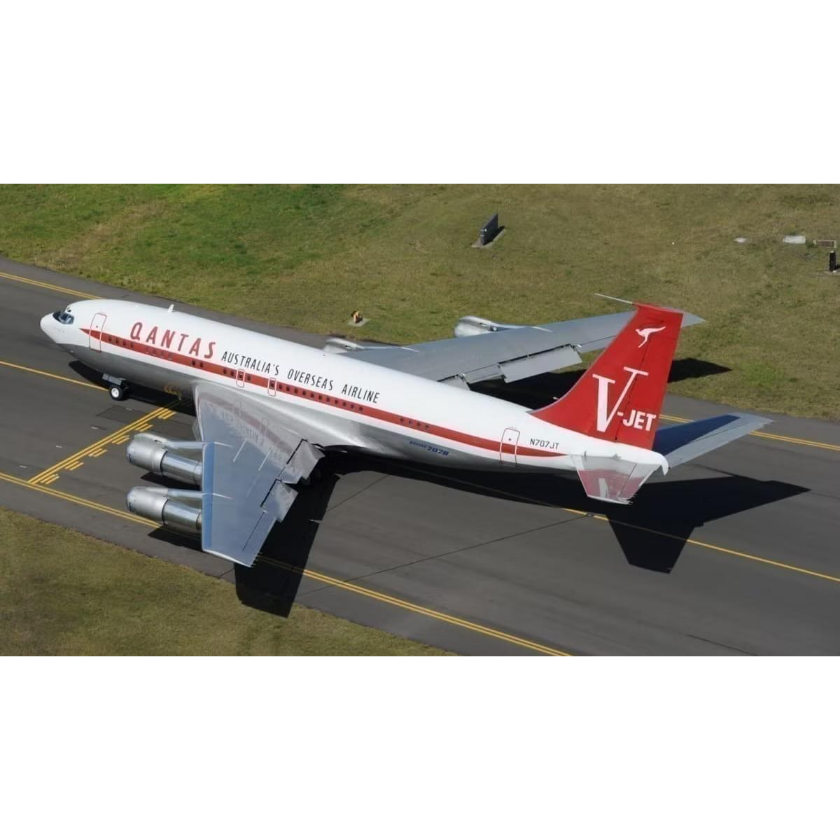

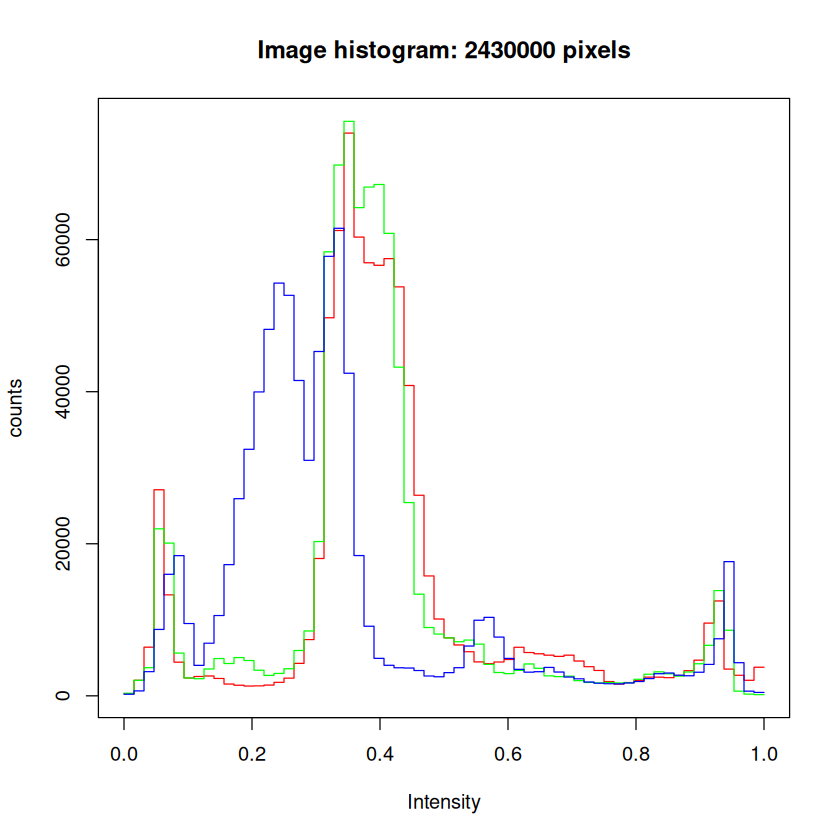

List of 18
 $ :Formal class 'Image' [package "EBImage"] with 2 slots
  .. ..@ .Data    : num [1:1200, 1:675, 1:3] 0.373 0.369 0.357 0.349 0.353 ...
  .. ..@ colormode: int 2
  .. ..$ dim: int [1:3] 1200 675 3
 $ :Formal class 'Image' [package "EBImage"] with 2 slots
  .. ..@ .Data    : num [1:2445, 1:2560, 1:3] 0.965 0.965 0.965 0.965 0.965 ...
  .. ..@ colormode: int 2
  .. ..$ dim: int [1:3] 2445 2560 3
 $ :Formal class 'Image' [package "EBImage"] with 2 slots
  .. ..@ .Data    : num [1:2022, 1:1349, 1:3] 0.576 0.576 0.576 0.576 0.576 ...
  .. ..@ colormode: int 2
  .. ..$ dim: int [1:3] 2022 1349 3
 $ :Formal class 'Image' [package "EBImage"] with 2 slots
  .. ..@ .Data    : num [1:547, 1:280, 1:3] 0.267 0.267 0.267 0.267 0.267 ...
  .. ..@ colormode: int 2
  .. ..$ dim: int [1:3] 547 280 3
 $ :Formal class 'Image' [package "EBImage"] with 2 slots
  .. ..@ .Data    : num [1:2022, 1:1349, 1:3] 0.576 0.576 0.576 0.576 0.576 ...
  .. ..@ colormode: int 2
  .. ..$ dim: int [1:3] 2022 13

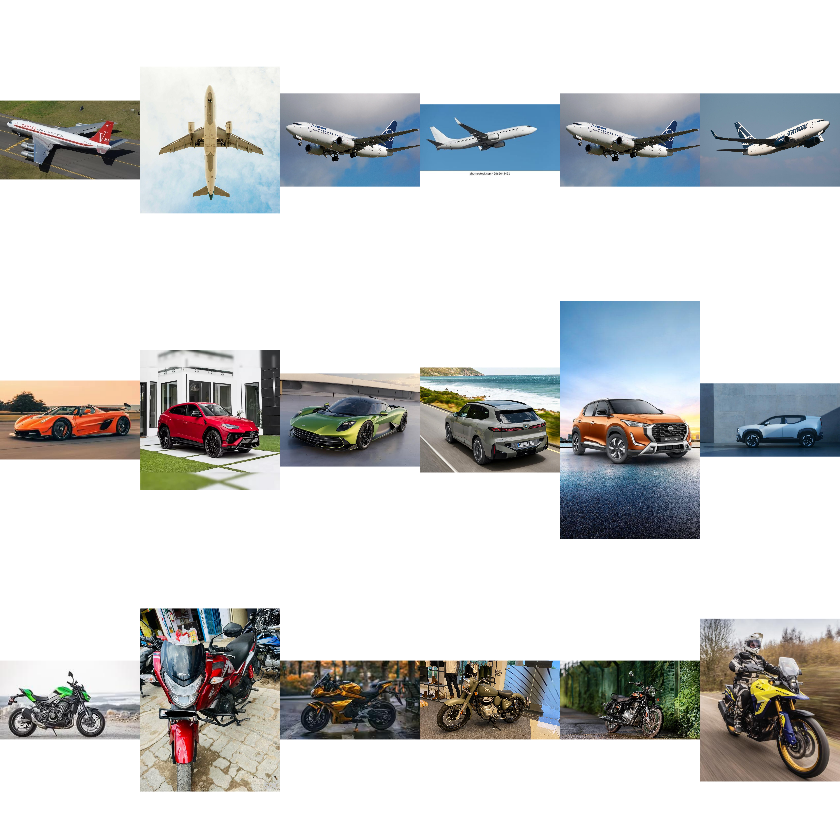

In [13]:
display(mypic[[1]], method = "raster")

summary(mypic[[1]])

hist(mypic[[1]])

par(mfrow = c(3, 6))
for (i in 1:18) plot(mypic[[i]])
par(mfrow = c(1, 1))

str(mypic)

In [14]:
for (i in 1:18) {
  mypic[[i]] <- resize(mypic[[i]], 28, 28)
}
str(mypic[[1]])

for (i in 1:18) {
  mypic[[i]] <- array_reshape(imageData(mypic[[i]]), c(28, 28, 3))
}
str(mypic[[1]])

Formal class 'Image' [package "EBImage"] with 2 slots
  ..@ .Data    : num [1:28, 1:28, 1:3] 0.396 0.36 0.414 0.381 0.404 ...
  ..@ colormode: int 2
  ..$ dim: int [1:3] 28 28 3
 num [1:28, 1:28, 1:3] 0.396 0.36 0.414 0.381 0.404 ...


In [15]:
trainx <- NULL
for (i in c(1:5, 7:11, 13:17)) {
  trainx <- rbind(trainx, mypic[[i]])
}
str(trainx)

testx <- rbind(mypic[[6]], mypic[[12]], mypic[[18]])
str(testx)

trainy <- c(0,0,0,0,0, 1,1,1,1,1, 2,2,2,2,2)
testy  <- c(0, 1, 2)

trainLabels <- to_categorical(trainy)
testLabels  <- to_categorical(testy)
trainLabels

 num [1:15, 1:2352] 0.396 0.965 0.581 0.267 0.581 ...
 num [1:3, 1:2352] 0.427 0.275 0.643 0.431 0.258 ...


1,0,0
1,0,0
1,0,0
1,0,0
1,0,0
0,1,0
0,1,0
0,1,0
0,1,0
0,1,0
0,0,1


In [16]:
set_random_seed(123)

model <- keras_model_sequential(input_shape = 2352) |>
  layer_dense(units = 256, activation = "relu") |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dense(units = 3, activation = "softmax")

summary(model)

model |> compile(
  loss = "categorical_crossentropy",
  optimizer = optimizer_rmsprop(),
  metrics = "accuracy"
)

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                     │ (None, 256)              │       602,368 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                   │ (None, 128)              │        32,896 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_2 (Dense)                   │ (None, 3)                │           387 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘
 Total params: 635,651 (2.42 MB)
 Trainable params: 635,651 (2.42 MB)
 Non-trainable params: 0 (0.00 B)


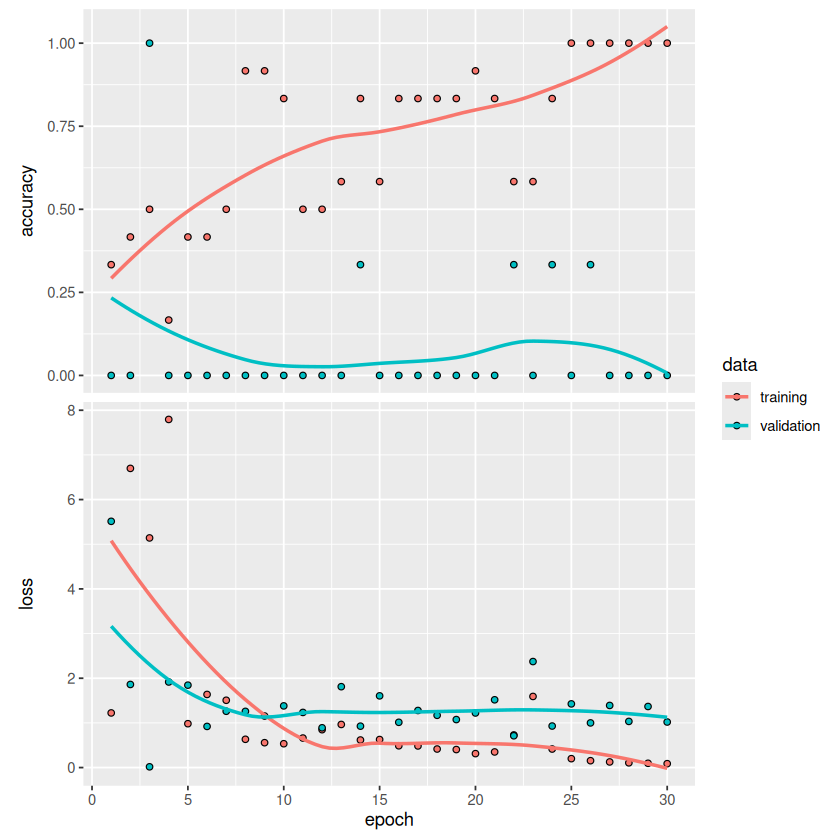

In [17]:
history <- model |> fit(
  trainx, trainLabels,
  epochs = 30,
  batch_size = 32,
  validation_split = 0.2
)

plot(history)

In [18]:
model |> evaluate(trainx, trainLabels)
prob_train <- predict(model, trainx)
pred_train <- max.col(prob_train, ties.method = "first") - 1
table(Predicted = pred_train, Actual = trainy)

model |> evaluate(testx, testLabels)
prob_test <- predict(model, testx)
round(prob_test, 3)
pred_test <- max.col(prob_test, ties.method = "first") - 1
table(Predicted = pred_test, Actual = testy)

$accuracy
[1] 0.8

$loss
[1] 0.2679946

         Actual
Predicted 0 1 2
        0 5 0 2
        1 0 5 1
        2 0 0 2

$accuracy
[1] 0.3333333

$loss
[1] 1.275721

0.871,0.036,0.093
0.759,0.158,0.083
0.180,0.662,0.158


         Actual
Predicted 0 1 2
        0 1 1 0
        1 0 0 1

[1] 2 0 2 1 0 1 0 0 2 1 0 2 2 1 1

$accuracy
[1] 0.8

$loss
[1] 0.2960484

         Actual
Predicted 0 1 2
        0 5 0 1
        1 0 3 0
        2 0 2 4

$accuracy
[1] 0.3333333

$loss
[1] 1.616038

0.947,0.011,0.042
0.945,0.027,0.028
0.195,0.499,0.306


         Actual
Predicted 0 1 2
        0 1 1 0
        1 0 0 1

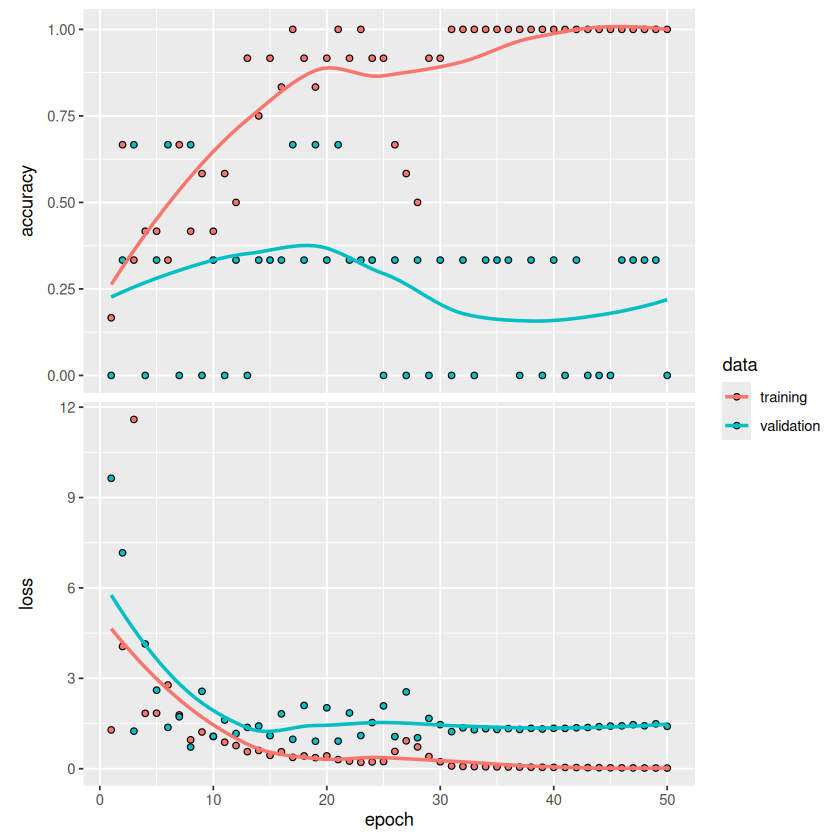

In [19]:
set.seed(123)
idx <- sample(1:15)
trainx_s      <- trainx[idx, ]
trainLabels_s <- trainLabels[idx, ]
trainy[idx]

set_random_seed(123)
model <- keras_model_sequential(input_shape = 2352) |>
  layer_dense(units = 256, activation = "relu") |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dense(units = 3, activation = "softmax")

model |> compile(
  loss = "categorical_crossentropy",
  optimizer = optimizer_rmsprop(),
  metrics = "accuracy"
)

history <- model |> fit(
  trainx_s, trainLabels_s,
  epochs = 50,
  batch_size = 32,
  validation_split = 0.2
)
plot(history)

model |> evaluate(trainx, trainLabels)
pred_train <- max.col(predict(model, trainx), ties.method = "first") - 1
table(Predicted = pred_train, Actual = trainy)

model |> evaluate(testx, testLabels)
prob_test <- predict(model, testx)
round(prob_test, 3)
pred_test <- max.col(prob_test, ties.method = "first") - 1
table(Predicted = pred_test, Actual = testy)

         Actual
Predicted 0 1 2
        0 5 0 0
        1 0 5 0
        2 0 0 5

0.932,0.012,0.056
0.857,0.100,0.043
0.094,0.664,0.242


         Actual
Predicted 0 1 2
        0 1 1 0
        1 0 0 1

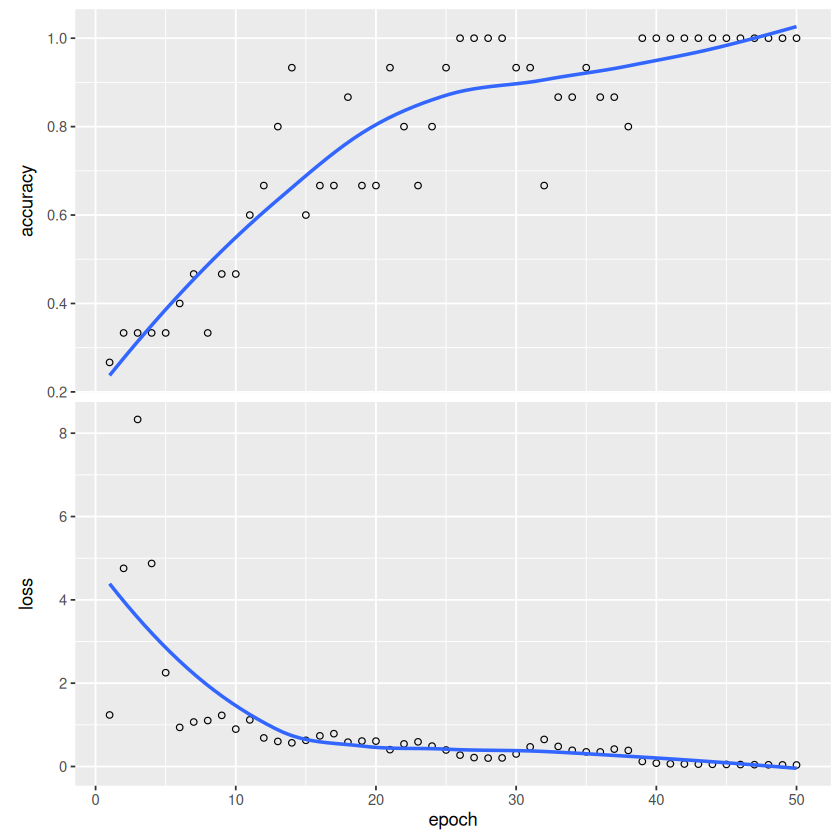

In [20]:
set_random_seed(123)
model <- keras_model_sequential(input_shape = 2352) |>
  layer_dense(units = 256, activation = "relu") |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dense(units = 3, activation = "softmax")

model |> compile(loss = "categorical_crossentropy",
                 optimizer = optimizer_rmsprop(),
                 metrics = "accuracy")

history <- model |> fit(trainx_s, trainLabels_s,
                        epochs = 50, batch_size = 32,
                        validation_split = 0)
plot(history)

pred_train <- max.col(predict(model, trainx), ties.method = "first") - 1
table(Predicted = pred_train, Actual = trainy)

prob_test <- predict(model, testx)
round(prob_test, 3)
pred_test <- max.col(prob_test, ties.method = "first") - 1
table(Predicted = pred_test, Actual = testy)

$accuracy
[1] 0.8

$loss
[1] 0.3274102

         Actual
Predicted 0 1
        0 5 2
        1 0 3

$accuracy
[1] 0.5

$loss
[1] 1.427291

0.979,0.021
0.941,0.059


         Actual
Predicted 0 1
        0 1 1

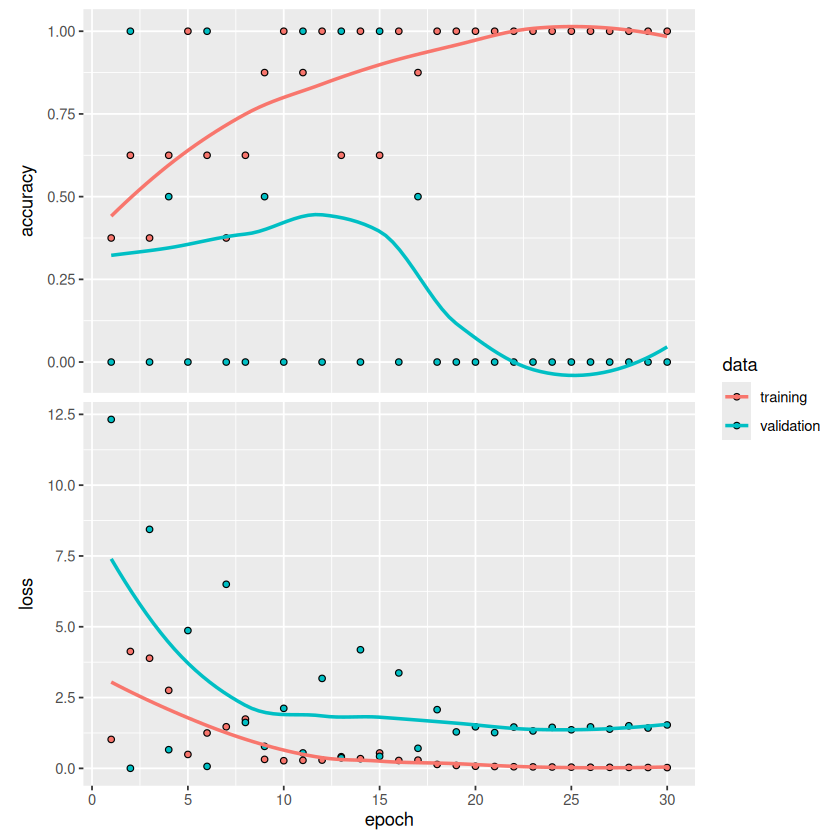

In [22]:
trainx2 <- NULL
for (i in c(1:5, 7:11)) trainx2 <- rbind(trainx2, mypic[[i]])
testx2  <- rbind(mypic[[6]], mypic[[12]])

trainy2 <- c(0,0,0,0,0, 1,1,1,1,1)
testy2  <- c(0, 1)
trainLabels2 <- to_categorical(trainy2)
testLabels2  <- to_categorical(testy2)

set_random_seed(123)
model2 <- keras_model_sequential(input_shape = 2352) |>
  layer_dense(units = 256, activation = "relu") |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dense(units = 2, activation = "softmax")

model2 |> compile(loss = "categorical_crossentropy",
                  optimizer = optimizer_rmsprop(),
                  metrics = "accuracy")

history2 <- model2 |> fit(trainx2, trainLabels2,
                          epochs = 30, batch_size = 32,
                          validation_split = 0.2)
plot(history2)

model2 |> evaluate(trainx2, trainLabels2)
pred2 <- max.col(predict(model2, trainx2), ties.method = "first") - 1
table(Predicted = pred2, Actual = trainy2)

model2 |> evaluate(testx2, testLabels2)
prob2 <- predict(model2, testx2)
round(prob2, 3)
pred_t2 <- max.col(prob2, ties.method = "first") - 1
table(Predicted = pred_t2, Actual = testy2)

,,Predicted,Actual
0.965,0.035,0,0
0.990,0.010,0,0
0.982,0.018,0,0
0.994,0.006,0,0
0.982,0.018,0,0
0.029,0.971,1,1
0.013,0.987,1,1
0.074,0.926,1,1
0.587,0.413,0,1
0.887,0.113,0,1


Only the first frame of the image stack is displayed.
To display all frames use 'all = TRUE'.



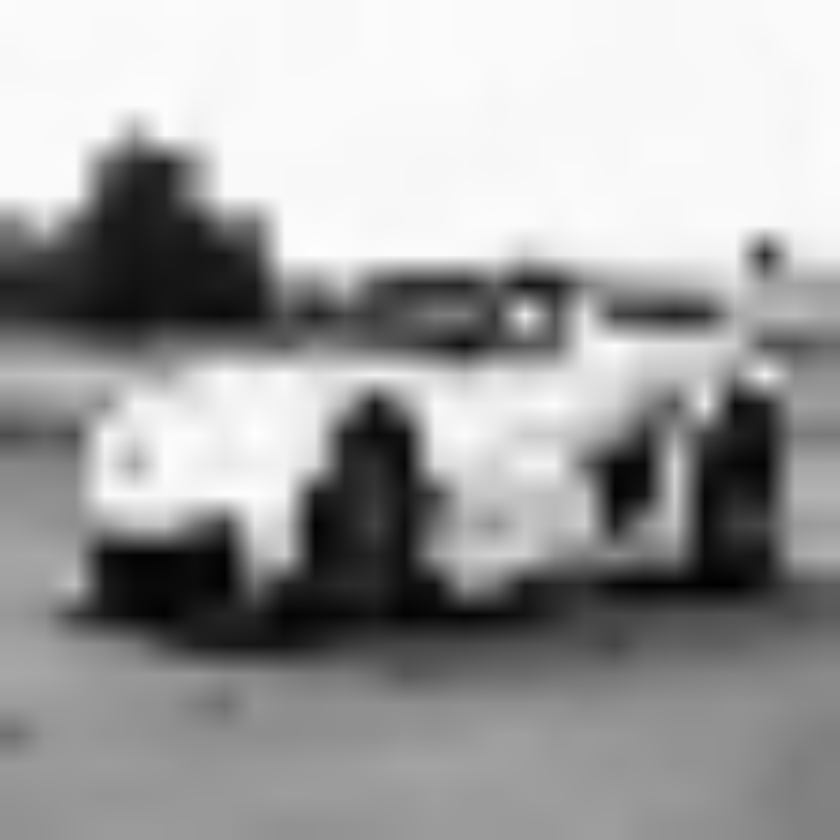

In [23]:
prob_tr2 <- predict(model2, trainx2)
cbind(round(prob_tr2, 3), Predicted = pred2, Actual = trainy2)

display(mypic[[7]], method = "raster")

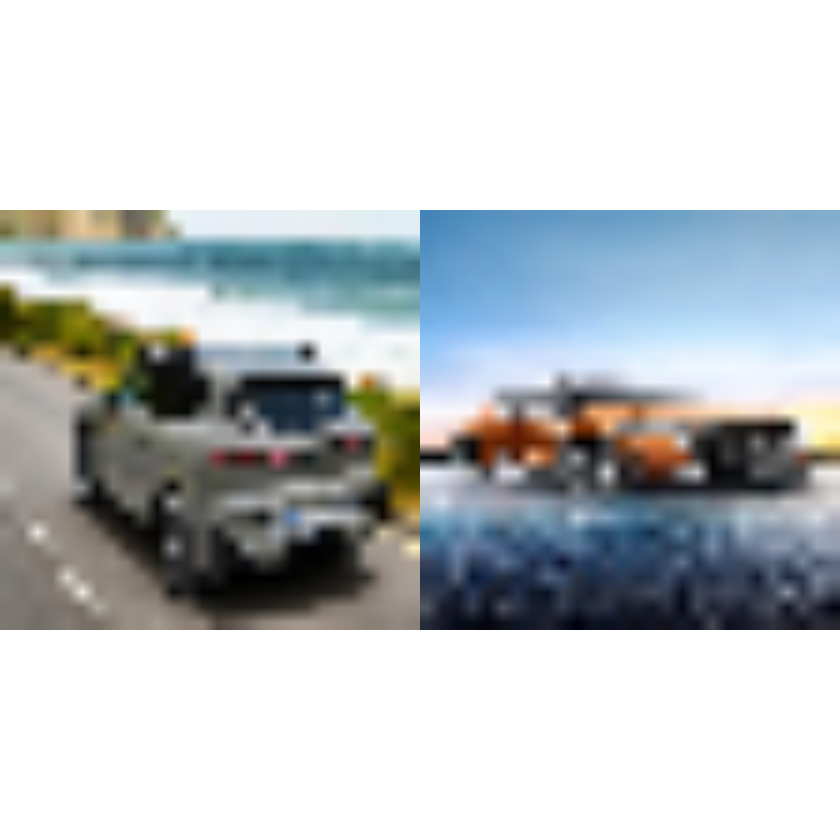

In [24]:
par(mfrow = c(1, 2))
display(Image(mypic[[10]], colormode = "Color"), method = "raster")
display(Image(mypic[[11]], colormode = "Color"), method = "raster")
par(mfrow = c(1, 1))

[1] "/content/c7.jpeg" "/content/c8.jpeg" "/content/c9.jpeg"


$accuracy
[1] 0.8

$loss
[1] 0.2741219

,,Predicted,Actual
0.965,0.035,0,0
0.990,0.010,0,0
0.982,0.018,0,0
0.994,0.006,0,0
0.982,0.018,0,0
0.029,0.971,1,1
0.013,0.987,1,1
0.074,0.926,1,1
0.721,0.279,0,1
0.716,0.284,0,1


         Actual
Predicted 0 1
        0 5 2
        1 0 3

$accuracy
[1] 1

$loss
[1] 0.08367415

,,Predicted,Actual
0.979,0.021,0,0
0.136,0.864,1,1


         Actual
Predicted 0 1
        0 1 0
        1 0 1

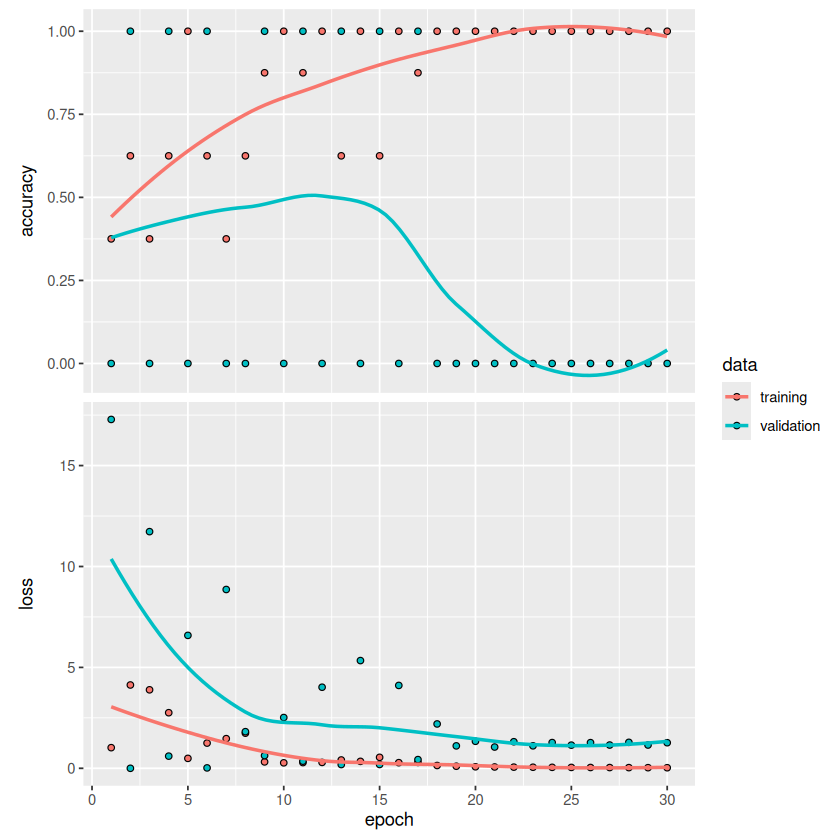

In [25]:
new <- sort(list.files("/content", pattern = "^c?[789]\\.jpe?g$",
                       ignore.case = TRUE, full.names = TRUE))
print(new)
targets <- c("/content/c4.jpg", "/content/c5.jpg", "/content/c6.jpg")
for (k in 1:3) {
  img <- image_convert(image_read(new[k]), format = "jpeg", colorspace = "sRGB")
  image_write(img, path = targets[k], format = "jpeg")
}

mypic <- list()
for (i in 1:18) mypic[[i]] <- readImage(pics[i])
for (i in 1:18) mypic[[i]] <- resize(mypic[[i]], 28, 28)
for (i in 1:18) mypic[[i]] <- array_reshape(imageData(mypic[[i]]), c(28, 28, 3))

trainx2 <- NULL
for (i in c(1:5, 7:11)) trainx2 <- rbind(trainx2, mypic[[i]])
testx2 <- rbind(mypic[[6]], mypic[[12]])

set_random_seed(123)
model2 <- keras_model_sequential(input_shape = 2352) |>
  layer_dense(units = 256, activation = "relu") |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dense(units = 2, activation = "softmax")
model2 |> compile(loss = "categorical_crossentropy",
                  optimizer = optimizer_rmsprop(), metrics = "accuracy")
history2 <- model2 |> fit(trainx2, trainLabels2, epochs = 30,
                          batch_size = 32, validation_split = 0.2)
plot(history2)

model2 |> evaluate(trainx2, trainLabels2)
prob_tr2 <- predict(model2, trainx2)
pred2 <- max.col(prob_tr2, ties.method = "first") - 1
cbind(round(prob_tr2, 3), Predicted = pred2, Actual = trainy2)
table(Predicted = pred2, Actual = trainy2)

model2 |> evaluate(testx2, testLabels2)
prob2 <- predict(model2, testx2)
pred_t2 <- max.col(prob2, ties.method = "first") - 1
cbind(round(prob2, 3), Predicted = pred_t2, Actual = testy2)
table(Predicted = pred_t2, Actual = testy2)

         Actual
Predicted 0 1 2
        0 5 0 0
        1 0 5 0
        2 0 0 5

,,,Predicted,Actual
0.953,0.009,0.038,0,0
0.004,0.986,0.010,1,1
0.074,0.705,0.222,1,2


         Actual
Predicted 0 1 2
        0 1 0 0
        1 0 1 1

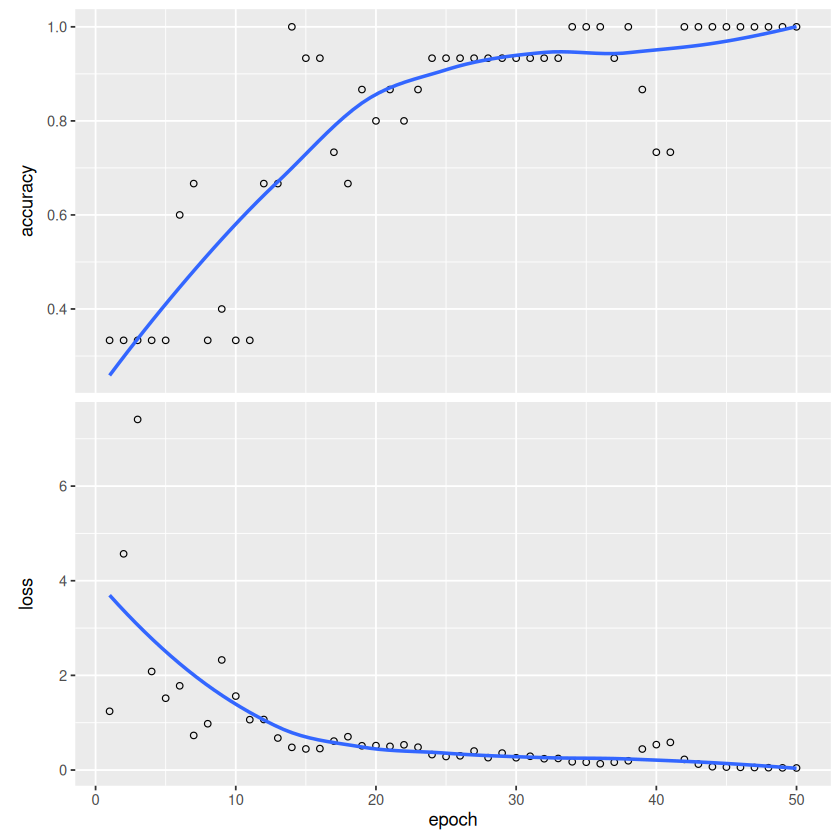

In [26]:
trainx <- NULL
for (i in c(1:5, 7:11, 13:17)) trainx <- rbind(trainx, mypic[[i]])
testx <- rbind(mypic[[6]], mypic[[12]], mypic[[18]])

set.seed(123)
idx <- sample(1:15)
trainx_s <- trainx[idx, ]
trainLabels_s <- trainLabels[idx, ]

set_random_seed(123)
model3 <- keras_model_sequential(input_shape = 2352) |>
  layer_dense(units = 256, activation = "relu") |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dense(units = 3, activation = "softmax")
model3 |> compile(loss = "categorical_crossentropy",
                  optimizer = optimizer_rmsprop(), metrics = "accuracy")
history3 <- model3 |> fit(trainx_s, trainLabels_s, epochs = 50,
                          batch_size = 32, validation_split = 0)
plot(history3)

pred3 <- max.col(predict(model3, trainx), ties.method = "first") - 1
table(Predicted = pred3, Actual = trainy)

prob3 <- predict(model3, testx)
pred_t3 <- max.col(prob3, ties.method = "first") - 1
cbind(round(prob3, 3), Predicted = pred_t3, Actual = testy)
table(Predicted = pred_t3, Actual = testy)

[1] "/content/b7.jpeg"


         Actual
Predicted 0 1 2
        0 5 0 0
        1 0 5 0
        2 0 0 5

,,,Predicted,Actual
0.953,0.009,0.038,0,0
0.004,0.986,0.010,1,1
0.006,0.959,0.036,1,2


         Actual
Predicted 0 1 2
        0 1 0 0
        1 0 1 1

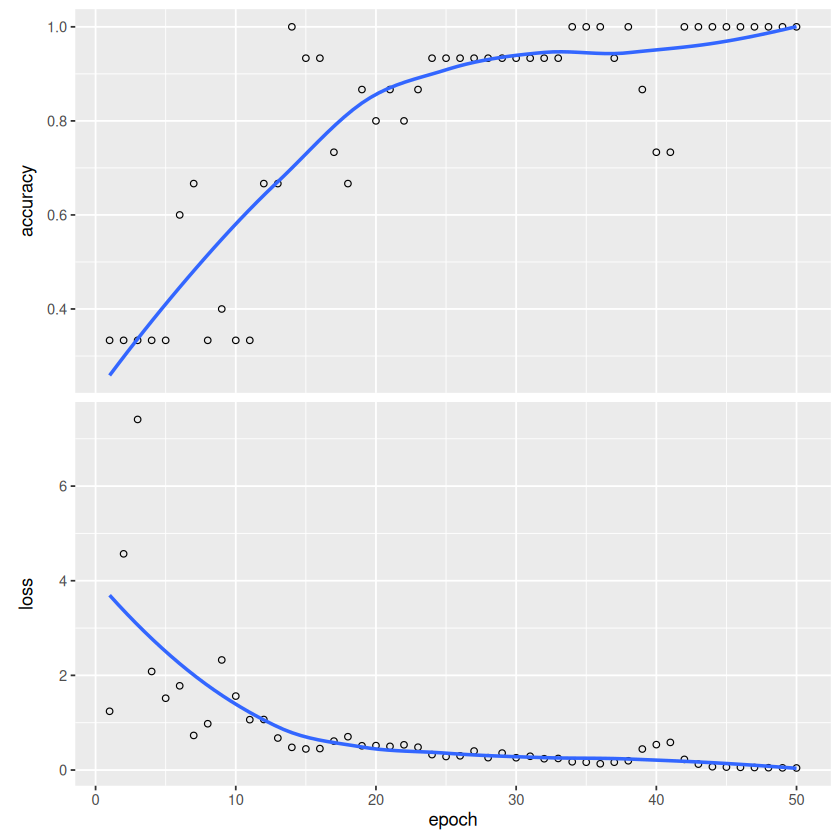

In [27]:
newb <- list.files("/content", pattern = "^b7\\.jpe?g$",
                   ignore.case = TRUE, full.names = TRUE)
print(newb)
img <- image_convert(image_read(newb[1]), format = "jpeg", colorspace = "sRGB")
image_write(img, path = "/content/b6.jpg", format = "jpeg")

mypic <- list()
for (i in 1:18) mypic[[i]] <- readImage(pics[i])
for (i in 1:18) mypic[[i]] <- resize(mypic[[i]], 28, 28)
for (i in 1:18) mypic[[i]] <- array_reshape(imageData(mypic[[i]]), c(28, 28, 3))

trainx <- NULL
for (i in c(1:5, 7:11, 13:17)) trainx <- rbind(trainx, mypic[[i]])
testx <- rbind(mypic[[6]], mypic[[12]], mypic[[18]])
trainx_s <- trainx[idx, ]

set_random_seed(123)
model3 <- keras_model_sequential(input_shape = 2352) |>
  layer_dense(units = 256, activation = "relu") |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dense(units = 3, activation = "softmax")
model3 |> compile(loss = "categorical_crossentropy",
                  optimizer = optimizer_rmsprop(), metrics = "accuracy")
history3 <- model3 |> fit(trainx_s, trainLabels_s, epochs = 50,
                          batch_size = 32, validation_split = 0)
plot(history3)

pred3 <- max.col(predict(model3, trainx), ties.method = "first") - 1
table(Predicted = pred3, Actual = trainy)

prob3 <- predict(model3, testx)
pred_t3 <- max.col(prob3, ties.method = "first") - 1
cbind(round(prob3, 3), Predicted = pred_t3, Actual = testy)
table(Predicted = pred_t3, Actual = testy)

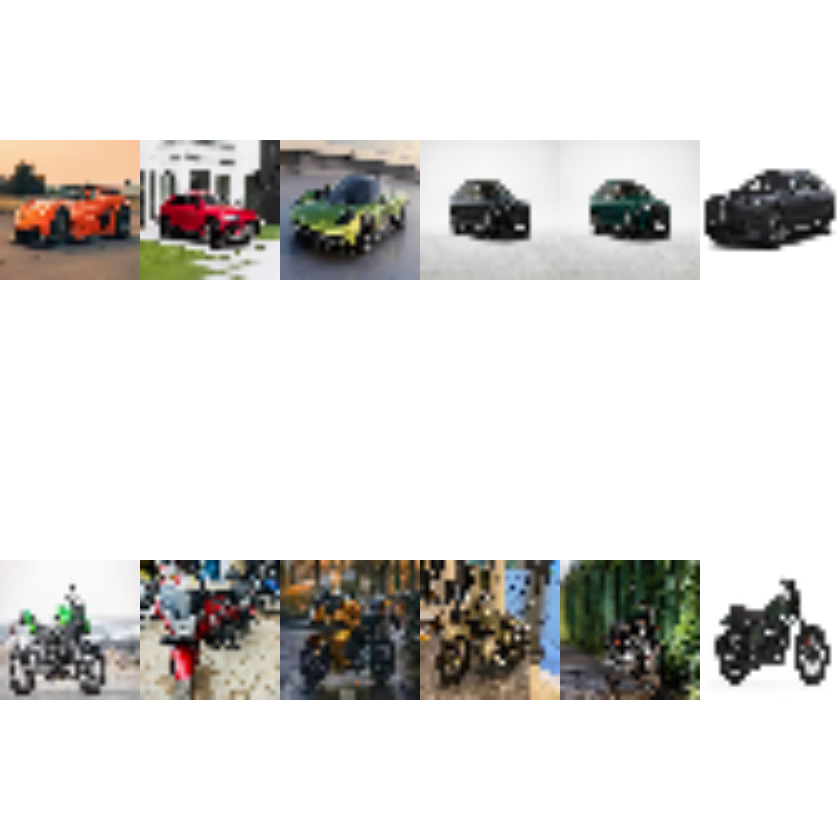

In [28]:
par(mfrow = c(2, 6))
for (i in 7:18) display(Image(mypic[[i]], colormode = "Color"), method = "raster")
par(mfrow = c(1, 1))

In [30]:
pics[c(15, 18)] <- pics[c(18, 15)]
pics

mypic <- list()
for (i in 1:18) mypic[[i]] <- readImage(pics[i])
for (i in 1:18) mypic[[i]] <- resize(mypic[[i]], 28, 28)
for (i in 1:18) mypic[[i]] <- array_reshape(imageData(mypic[[i]]), c(28, 28, 3))

trainx <- NULL
for (i in c(1:5, 7:11, 13:17)) trainx <- rbind(trainx, mypic[[i]])
testx <- rbind(mypic[[6]], mypic[[12]], mypic[[18]])
trainx_s <- trainx[idx, ]

set_random_seed(123)
model3 <- keras_model_sequential(input_shape = 2352) |>
  layer_dense(units = 256, activation = "relu") |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dense(units = 3, activation = "softmax")
model3 |> compile(loss = "categorical_crossentropy",
                  optimizer = optimizer_rmsprop(), metrics = "accuracy")
history3 <- model3 |> fit(trainx_s, trainLabels_s, epochs = 50,
                          batch_size = 32, validation_split = 0)

pred3 <- max.col(predict(model3, trainx), ties.method = "first") - 1
table(Predicted = pred3, Actual = trainy)

prob3 <- predict(model3, testx)
pred_t3 <- max.col(prob3, ties.method = "first") - 1
cbind(round(prob3, 3), Predicted = pred_t3, Actual = testy)
table(Predicted = pred_t3, Actual = testy)

[1] "p1.jpg" "p2.jpg" "p3.jpg" "p4.jpg" "p5.jpg" "p6.jpg" "c1.jpg" "c2.jpg"
 [9] "c3.jpg" "c4.jpg" "c5.jpg" "c6.jpg" "b1.jpg" "b2.jpg" "b6.jpg" "b4.jpg"
[17] "b5.jpg" "b3.jpg"

         Actual
Predicted 0 1 2
        0 5 0 0
        1 0 5 0
        2 0 0 5

,,,Predicted,Actual
0.965,0.009,0.027,0,0
0.003,0.830,0.167,1,1
0.312,0.279,0.409,2,2


         Actual
Predicted 0 1 2
        0 1 0 0
        1 0 1 0
        2 0 0 1